In [1]:
# Run from the notebooks directory so the original analysis paths resolve.
from pathlib import Path

project_dir = Path.cwd().parent
dataset_dir = project_dir / "Description and Sample of the DataSet-20261006"
required_files = (
    project_dir / "inspect_dataset.py",
    dataset_dir / "MetadatabyAnnotation.xlsx",
    dataset_dir / "MetadatabyNoduleMaxVoting.xlsx",
)
required_directories = (
    project_dir / "results",
    *(dataset_dir / image_type / folder
      for image_type in ("CT", "VOIs") for folder in ("image", "nodule_mask")),
)
missing = [path for path in required_files if not path.is_file()]
missing.extend(path for path in required_directories if not path.is_dir())
if missing:
    raise FileNotFoundError(
        "Run from the repository's notebooks directory. Check these paths:\n"
        + "\n".join(str(path) for path in missing)
    )
print("Both workbooks, all four imaging folders, and the results folder are available.")

Both workbooks, all four imaging folders, and the results folder are available.


In [2]:
%run ../inspect_dataset.py

Dataset exists: True
Image directory exists: True
Mask directory exists: True

Images: 994
Masks: 996

Masks without image:
LIDC-IDRI-1002_R_1.nii.gz
LIDC-IDRI-1002_R_2.nii.gz

Images without mask:


In [3]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import sklearn
import nibabel as nib

print("Python:", sys.version)
print("Python executable:", sys.executable)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NiBabel:", nib.__version__)

Python: 3.14.7 (v3.14.7:823f0323ee6, Aug  5 2026, 07:07:01) [Clang 21.0.0 (clang-2100.1.1.101)]
Python executable: /Users/macbook/Documents/LUNA16DataAnalysis/.venv/bin/python
NumPy: 2.5.4
Pandas: 3.0.6
Matplotlib: 3.11.2
Scikit-learn: 1.9.1
NiBabel: 5.4.2


In [4]:
from pathlib import Path

# Project root (notebook inside notebooks/)
PROJECT_ROOT = Path.cwd().parent

# Dataset location
DATASET_DIR = PROJECT_ROOT / "Description and Sample of the DataSet-20261006"

# Metadata
metadata_path = DATASET_DIR / "MetadatabyAnnotation.xlsx"

# Load Excel file
df = pd.read_excel(metadata_path)

print("Dataset dimensions:", df.shape)

display(df.head())

Dataset dimensions: (3674, 33)


,patient_id,nodule_id,seriesuid,coordX,coordY,coordZ,diameter_mm,bboxLowX,bboxLowY,bboxLowZ,...,Margin_value,Sphericity,Sphericity_value,Spiculation,Spiculation_value,Subtlety,Subtlety_value,Texture,Texture_value,len_mal_details
0,LIDC-IDRI-0001,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,56.208405,86.343413,-115.867579,23.350644,43.531250,68.768753,-125.0,...,3,Ovoid,3,Near Marked Spiculation,4,Obvious,5,Solid,5,4
1,LIDC-IDRI-0001,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,56.208405,86.343413,-115.867579,23.350644,43.531250,68.768753,-125.0,...,4,Ovoid/Round,4,Marked Spiculation,5,Obvious,5,Solid,5,4
2,LIDC-IDRI-0001,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,56.208405,86.343413,-115.867579,23.350644,43.531250,68.768753,-125.0,...,2,Ovoid,3,Medium Spiculation,3,Obvious,5,Solid,5,4
3,LIDC-IDRI-0001,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,56.208405,86.343413,-115.867579,23.350644,43.531250,68.768753,-125.0,...,4,Round,5,Marked Spiculation,5,Obvious,5,Solid/Mixed,4,4
4,LIDC-IDRI-0003,2,1.3.6.1.4.1.14519.5.2.1.6279.6001.170706757615...,72.286707,76.900239,-190.458928,21.453729,57.488893,63.984216,-199.0,...,3,Ovoid,3,Nearly No Spiculation,2,Obvious,5,Part Solid/Mixed,3,4


In [5]:
df.info

<bound method DataFrame.info of           patient_id  nodule_id  \
0     LIDC-IDRI-0001          1   
1     LIDC-IDRI-0001          1   
2     LIDC-IDRI-0001          1   
3     LIDC-IDRI-0001          1   
4     LIDC-IDRI-0003          2   
...              ...        ...   
3669  LIDC-IDRI-1011          2   
3670  LIDC-IDRI-1011          3   
3671  LIDC-IDRI-1011          3   
3672  LIDC-IDRI-1011          3   
3673  LIDC-IDRI-1011          3   

                                              seriesuid      coordX  \
0     1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...   56.208405   
1     1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...   56.208405   
2     1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...   56.208405   
3     1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...   56.208405   
4     1.3.6.1.4.1.14519.5.2.1.6279.6001.170706757615...   72.286707   
...                                                 ...         ...   
3669  1.3.6.1.4.1.14519.5.2.1.6279.6001.2721233982

In [6]:
# Basic dataset statistics

print("Total annotations:", len(df))
print("Unique patients:", df["patient_id"].nunique())

nodule_cols = ["patient_id", "nodule_id"]

#Check how many patient we have
print(
    "Unique nodules:",
    df[nodule_cols].drop_duplicates().shape[0]
)

#Check if there is any missing value
print("\nMissing values:")
print(df.isnull().sum())


print("\nAnnotations per nodule:")
print(df.groupby(nodule_cols).size().value_counts().sort_index())

Total annotations: 3674
Unique patients: 551
Unique nodules: 996

Missing values:
patient_id                 0
nodule_id                  0
seriesuid                  0
coordX                     0
coordY                     0
coordZ                     0
diameter_mm                0
bboxLowX                   0
bboxLowY                   0
bboxLowZ                   0
bboxHighX                  0
bboxHighY                  0
bboxHighZ                  0
Malignancy                 0
Malignancy_value           0
anotation_id               0
Calcification              0
Calcification_value        0
InternalStructure          0
InternalStructure_value    0
Lobulation                 0
Lobulation_value           0
Margin                     0
Margin_value               0
Sphericity                 0
Sphericity_value           0
Spiculation                0
Spiculation_value          0
Subtlety                   0
Subtlety_value             0
Texture                    0
Texture_value      

In [7]:
# Create a nodule-level dataset

nodule_df = (
    df.groupby(["patient_id", "nodule_id"], as_index=False)
    .agg(
        diameter_mm=("diameter_mm", "median"),
        n_annotations=("anotation_id", "size"),
        min_diameter=("diameter_mm", "min"),
        max_diameter=("diameter_mm", "max")
    )
)

print("Number of unique nodules:", len(nodule_df))

display(nodule_df.head())

Number of unique nodules: 996


,patient_id,nodule_id,diameter_mm,n_annotations,min_diameter,max_diameter
0,LIDC-IDRI-0001,1,23.350644,4,23.350644,23.350644
1,LIDC-IDRI-0003,2,21.453729,4,21.453729,21.453729
2,LIDC-IDRI-0003,3,8.785833,4,8.785833,8.785833
3,LIDC-IDRI-0003,4,12.823120,4,12.823120,12.823120
4,LIDC-IDRI-0004,1,4.560710,4,4.560710,4.560710


Matplotlib is building the font cache; this may take a moment.


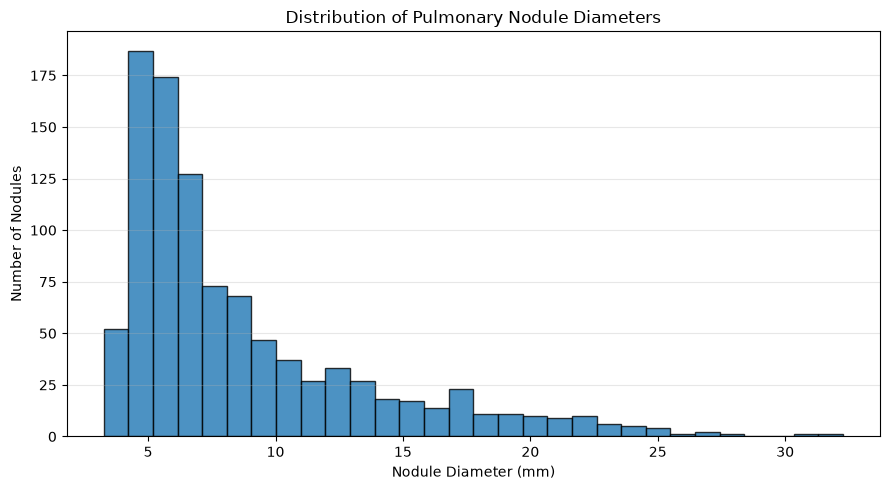

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    nodule_df["diameter_mm"],
    bins=30,
    edgecolor="black",
    alpha=0.8
)

plt.title("Distribution of Pulmonary Nodule Diameters")
plt.xlabel("Nodule Diameter (mm)")
plt.ylabel("Number of Nodules")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    PROJECT_ROOT / "results" / "nodule_diameter_distribution.png",
    dpi=300
)

plt.show()

In [9]:
nodule_df["diameter_difference"] = (
    nodule_df["max_diameter"] -
    nodule_df["min_diameter"]
)

print(nodule_df["diameter_mm"].describe())

print(
    "\nNodules with different diameter values:",
    (nodule_df["diameter_difference"] > 1e-6).sum()
)

display(
    nodule_df.sort_values(
        "diameter_difference",
        ascending=False
    ).head(10)
)

count    996.000000
mean       8.694826
std        4.939517
min        3.253443
25%        5.232312
50%        6.769231
75%       10.444362
max       32.270030
Name: diameter_mm, dtype: float64

Nodules with different diameter values: 1


,patient_id,nodule_id,diameter_mm,n_annotations,min_diameter,max_diameter,diameter_difference
400,LIDC-IDRI-0332,1,11.475523,9,11.475523,24.663360,13.187836
466,LIDC-IDRI-0415,3,6.853377,4,6.853377,6.853377,0.000000
722,LIDC-IDRI-0686,9,6.269450,3,6.269450,6.269450,0.000000
850,LIDC-IDRI-0843,4,8.413885,4,8.413885,8.413885,0.000000
914,LIDC-IDRI-0912,2,4.355736,3,4.355736,4.355736,0.000000
946,LIDC-IDRI-0942,2,11.139832,4,11.139832,11.139832,0.000000
962,LIDC-IDRI-0978,2,7.478521,4,7.478521,7.478521,0.000000
970,LIDC-IDRI-0994,2,7.283783,4,7.283783,7.283783,0.000000
974,LIDC-IDRI-0999,4,3.661015,4,3.661015,3.661015,0.000000
977,LIDC-IDRI-1002,1,16.381276,4,16.381276,16.381276,0.000000


Total nodules: 996
Nodules with unique malignancy mode: 797
Nodules with ambiguous malignancy mode: 199


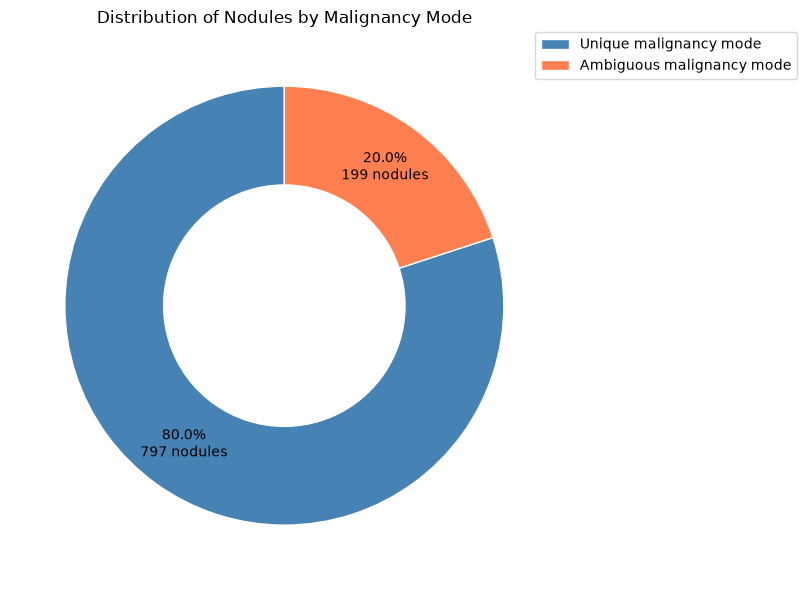

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# Identify each nodule using its patient and nodule IDs
nodule_identifiers = ["patient_id", "nodule_id"]

# Calculate the median diameter for each nodule
median_diameter_per_nodule = (
    df.groupby(nodule_identifiers)["diameter_mm"].median()
)

# Find the most frequent malignancy score for each nodule
def get_most_frequent_malignancy(malignancy_scores):
    most_frequent_scores = malignancy_scores.mode()

    # If multiple scores are equally frequent, leave the result undefined
    if len(most_frequent_scores) > 1:
        return pd.NA

    return most_frequent_scores.iloc[0]


# Calculate the representative malignancy score for each nodule
malignancy_per_nodule = (
    df.groupby(nodule_identifiers)["Malignancy_value"]
    .agg(get_most_frequent_malignancy)
)

# Combine diameter and malignancy into one dataset
nodule_analysis = pd.concat(
    [median_diameter_per_nodule, malignancy_per_nodule],
    axis=1
).reset_index()


# Count nodules with and without a unique malignancy mode
total_nodules = len(nodule_analysis)

ambiguous_nodules = (
    nodule_analysis["Malignancy_value"].isna().sum()
)

nodules_with_unique_mode = total_nodules - ambiguous_nodules

print("Total nodules:", total_nodules)
print("Nodules with unique malignancy mode:", nodules_with_unique_mode)
print("Nodules with ambiguous malignancy mode:", ambiguous_nodules)


# Visualize the distribution
# Calculate the percentage and number of nodules for each category
nodule_counts = [
    nodules_with_unique_mode,
    ambiguous_nodules
]

def format_percentage_and_count(percentage):

    # Calculate the number of nodules
    nodule_count = round(total_nodules * percentage / 100)

    # Format the percentage
    percentage_text = f"{percentage:.1f}%"

    # Format the number of nodules
    count_text = f"{nodule_count} nodules"

    # Display both values on separate lines
    return percentage_text + "\n" + count_text

# Create donut chart
fig, ax = plt.subplots(figsize=(8, 6))

wedges, texts, autotexts = ax.pie(
    nodule_counts,
    autopct=format_percentage_and_count,
    startangle=90,
    colors=["steelblue", "coral"],
    pctdistance=0.78,
    wedgeprops={"width": 0.45, "edgecolor": "white"},
    textprops={"fontsize": 10}
)

# Add legend to the upper-right corner
fig.legend(
    wedges,
    [
        "Unique malignancy mode",
        "Ambiguous malignancy mode"
    ],
    loc="upper right",
    bbox_to_anchor=(1.15, 0.95),
    frameon=True
)

ax.set_title("Distribution of Nodules by Malignancy Mode")

plt.tight_layout()
plt.savefig(
    PROJECT_ROOT / "results" / "malignancy_mode_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


Malignancy 1: 115 nodules
Malignancy 2: 110 nodules
Malignancy 3: 329 nodules
Malignancy 4: 107 nodules
Malignancy 5: 136 nodules


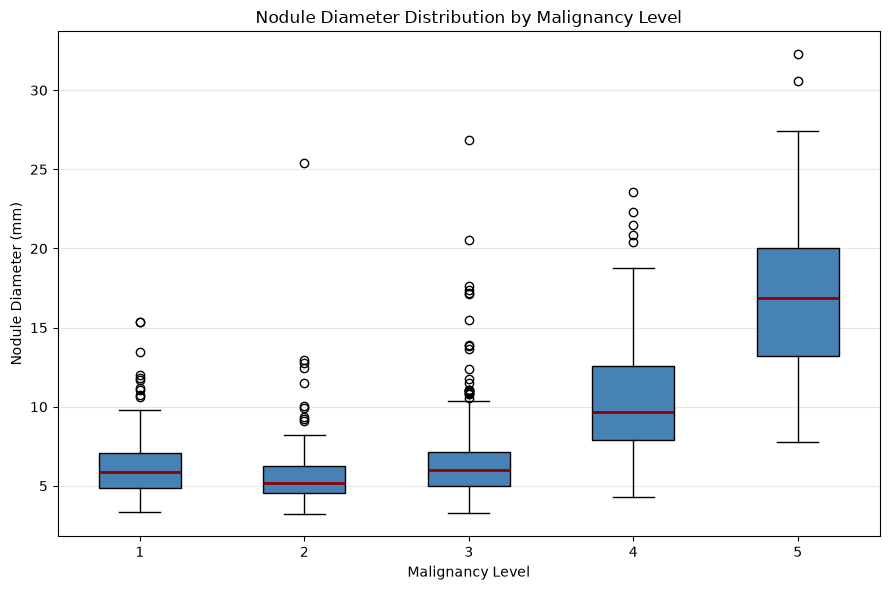

In [11]:
# Exclude nodules without a unique malignancy mode
nodules_with_clear_malignancy = nodule_analysis.dropna(
    subset=["Malignancy_value"]
).copy()

# Prepare diameter values for each malignancy level
diameters_by_malignancy = []

for malignancy_level in range(1, 6):

    nodules_in_level = nodules_with_clear_malignancy[
        nodules_with_clear_malignancy["Malignancy_value"] == malignancy_level
    ]

    diameters = nodules_in_level["diameter_mm"]

    diameters_by_malignancy.append(diameters)

    print(f"Malignancy {malignancy_level}: {len(diameters)} nodules")


# Create boxplot
fig, ax = plt.subplots(figsize=(9, 6))

ax.boxplot(
    diameters_by_malignancy,
    tick_labels=["1", "2", "3", "4", "5"],
    patch_artist=True,
    boxprops={"facecolor": "steelblue", "alpha": 1},
    medianprops={"color": "darkred", "linewidth": 2}
)

ax.set_title("Nodule Diameter Distribution by Malignancy Level")
ax.set_xlabel("Malignancy Level")
ax.set_ylabel("Nodule Diameter (mm)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Save figure before displaying it
fig.savefig(
    PROJECT_ROOT / "results" / "diameter_vs_malignancy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
# Group nodule diameters by malignancy level
diameters_grouped_by_malignancy = (
    nodules_with_clear_malignancy
    .groupby("Malignancy_value")["diameter_mm"]
)

# Calculate the number of nodules and median diameter
diameter_statistics = diameters_grouped_by_malignancy.agg(
    ["count", "median"]
)

# Calculate first and third quartiles
diameter_statistics["Q1"] = diameters_grouped_by_malignancy.quantile(0.25)
diameter_statistics["Q3"] = diameters_grouped_by_malignancy.quantile(0.75)

# Calculate the interquartile range
diameter_statistics["IQR"] = (
    diameter_statistics["Q3"] - diameter_statistics["Q1"]
)

# Display the results
display(diameter_statistics.round(2))

,count,median,Q1,Q3,IQR
Malignancy_value,,,,,
1,115,5.85,4.85,7.10,2.25
2,110,5.19,4.56,6.25,1.69
3,329,5.99,4.99,7.17,2.17
4,107,9.70,7.89,12.59,4.70
5,136,16.90,13.20,20.06,6.86


## Extended exploratory analysis

The analyses above use individual annotations. The following sections use one row per
nodule for diagnosis comparisons and return to individual annotations for agreement.
Run the notebook from the `notebooks` directory so its existing relative paths resolve.

In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Rectangle
from matplotlib.ticker import PercentFormatter

results_dir = PROJECT_ROOT / "results"
voting_path = DATASET_DIR / "MetadatabyNoduleMaxVoting.xlsx"
annotations_path = DATASET_DIR / "MetadatabyAnnotation.xlsx"
missing_workbooks = [path for path in (voting_path, annotations_path) if not path.is_file()]
if missing_workbooks:
    raise FileNotFoundError("Place the required workbooks in the dataset folder: "
                            + ", ".join(str(path) for path in missing_workbooks))
if not results_dir.is_dir():
    raise FileNotFoundError(f"Expected results folder: {results_dir}")

nodule_keys = ["patient_id", "nodule_id"]
diagnosis_column = "Diagnosis_value"
diagnosis_names = {0: "Benign", 1: "Malign"}
diagnosis_order = list(diagnosis_names.values())
diagnosis_colors = ["#197E87", "#B94E39"]
features = ["Spiculation", "Lobulation", "Sphericity", "Texture", "Margin"]
feature_columns = [f"{feature}_value" for feature in features]

nodules = pd.read_excel(voting_path, sheet_name="ML4PM_MetadatabyNoduleMaxVoting")
required_voting = set(nodule_keys + [diagnosis_column, "diameter_mm", "Subtlety_value"]
                      + features + feature_columns)
missing_columns = sorted(required_voting - set(nodules.columns))
if missing_columns:
    raise ValueError(f"Voting workbook is missing columns: {missing_columns}")
if (len(nodules) != 996 or nodules[nodule_keys].isna().any().any()
        or nodules.duplicated(nodule_keys).any()):
    raise ValueError("Expected 996 unique nodules identified by patient_id and nodule_id.")
if (nodules[diagnosis_column].isna().any()
        or set(nodules[diagnosis_column]) != set(diagnosis_names)):
    raise ValueError("Expected a diagnosis of 0 or 1 for every nodule and both groups.")
if nodules[list(required_voting)].isna().any().any():
    raise ValueError("Required nodule features are missing values. Review the workbook.")
nodules["Diagnosis_group"] = nodules[diagnosis_column].map(diagnosis_names)
print(f"Loaded {len(nodules):,} unique nodules from {voting_path.name}.")

Loaded 996 unique nodules from MetadatabyNoduleMaxVoting.xlsx.


### 1. Benign and malign nodules

,Nodules,Share (%)
Diagnosis_group,,
Benign,650,65.3
Malign,346,34.7


,count,mean,std,min,Q1,Median,Q3,max,IQR
Diagnosis_group,,,,,,,,,
Benign,650.0,6.25,2.34,3.25,4.86,5.74,6.92,26.84,2.06
Malign,346.0,13.28,5.27,4.33,8.99,12.46,16.94,32.27,7.95


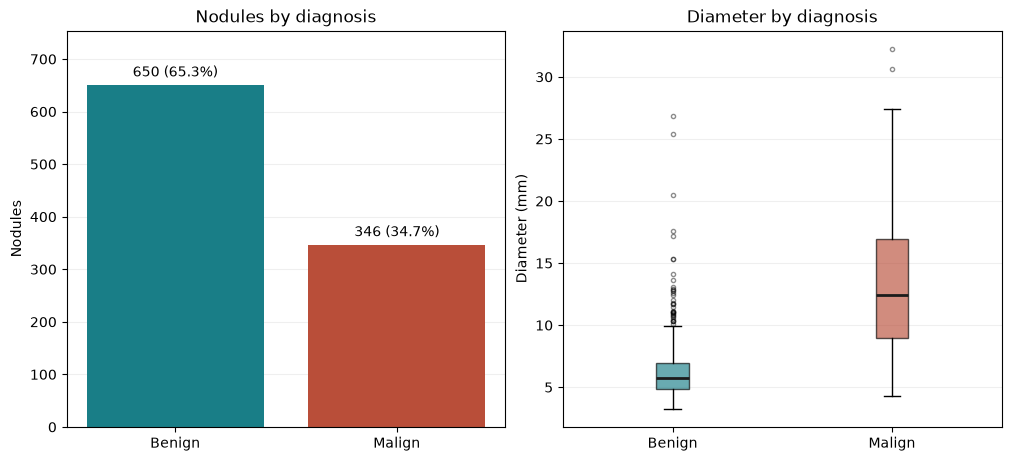

In [14]:
diagnosis_counts = nodules["Diagnosis_group"].value_counts().reindex(diagnosis_order)
diagnosis_summary = diagnosis_counts.rename("Nodules").to_frame()
diagnosis_summary["Share (%)"] = diagnosis_counts / len(nodules) * 100
diameter_summary = (
    nodules.groupby("Diagnosis_group")["diameter_mm"]
    .describe().reindex(diagnosis_order)
    .rename(columns={"25%": "Q1", "50%": "Median", "75%": "Q3"})
)
diameter_summary["IQR"] = diameter_summary["Q3"] - diameter_summary["Q1"]
display(diagnosis_summary.round(1), diameter_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
bars = axes[0].bar(diagnosis_order, diagnosis_counts, color=diagnosis_colors)
axes[0].bar_label(bars, labels=[
    f"{count:,} ({count / len(nodules):.1%})" for count in diagnosis_counts
], padding=4)
axes[0].set(title="Nodules by diagnosis", ylabel="Nodules",
            ylim=(0, diagnosis_counts.max() * 1.16))
boxplot = axes[1].boxplot(
    [nodules.loc[nodules["Diagnosis_group"].eq(group), "diameter_mm"]
     for group in diagnosis_order],
    tick_labels=diagnosis_order, patch_artist=True,
    medianprops={"color": "#1B1B1B", "linewidth": 2},
    flierprops={"marker": ".", "alpha": 0.45},
)
for box, color in zip(boxplot["boxes"], diagnosis_colors):
    box.set_facecolor(color)
    box.set_alpha(0.65)
axes[1].set(title="Diameter by diagnosis", ylabel="Diameter (mm)")
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
fig.savefig(results_dir / "eda_diagnosis_and_diameter.png", dpi=220)
plt.show()

Of the 996 nodules, 650 (65.3%) are labeled Benign and 346 (34.7%) Malign.
The median diameter is 5.74 mm for Benign nodules and 12.46 mm for Malign
nodules. The groups overlap, and the Malign group has a wider middle 50%.

### 2. Morphology and texture by diagnosis

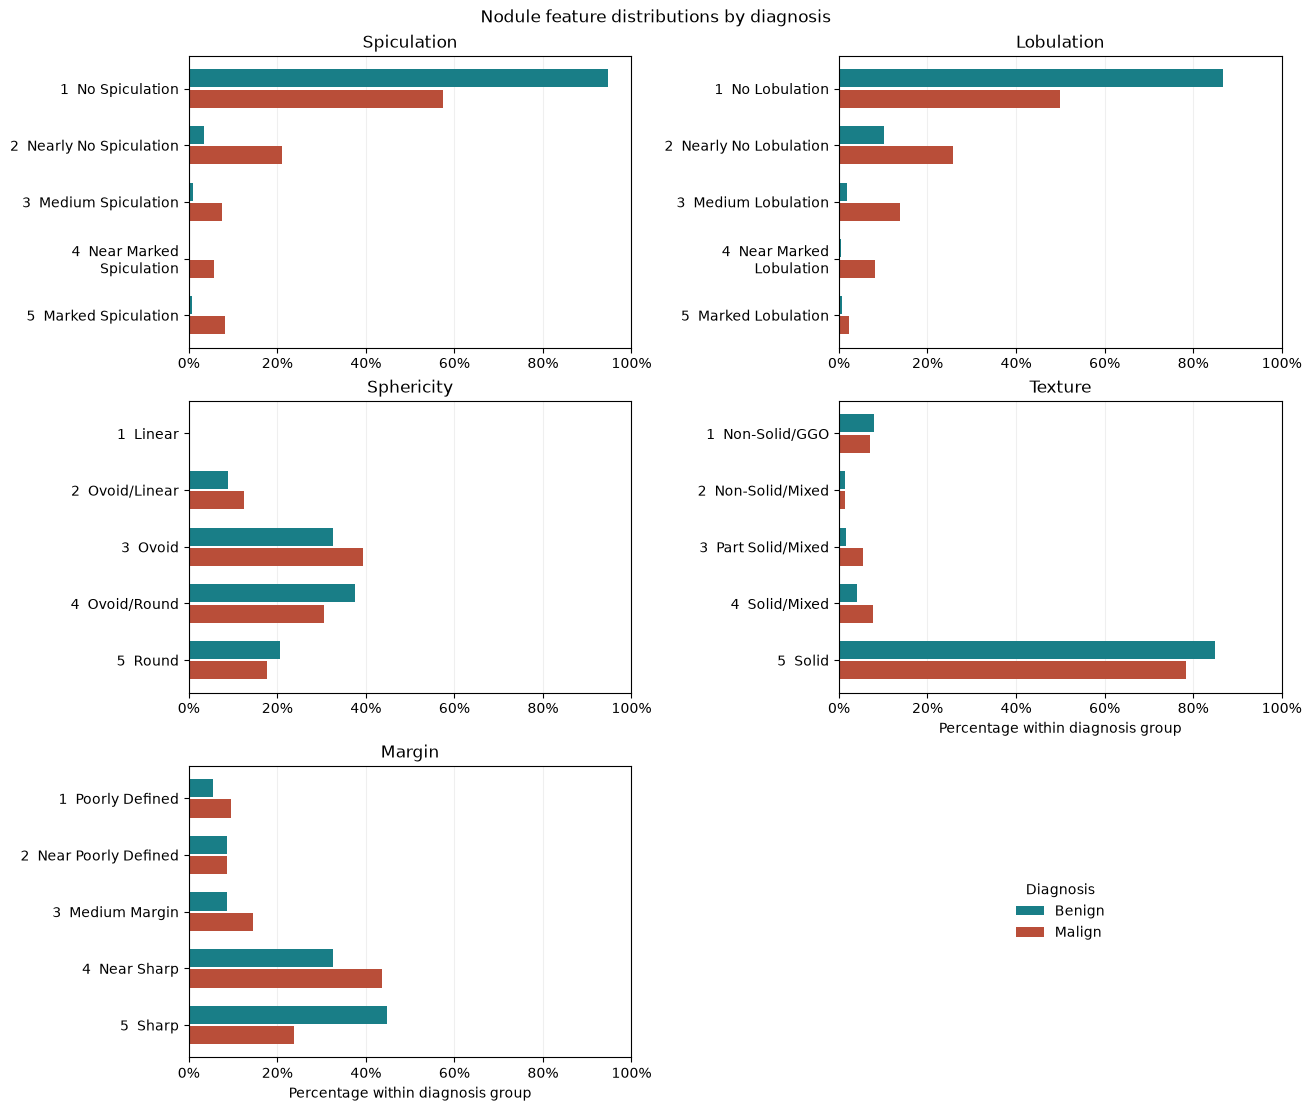

In [15]:
from textwrap import fill

fig, axes = plt.subplots(3, 2, figsize=(13, 11), layout="constrained", sharex=True)
for feature, score_column, ax in zip(features, feature_columns, axes.flat):
    labels = (
        nodules[[score_column, feature]].drop_duplicates()
        .sort_values(score_column).set_index(score_column)[feature]
    )
    if not labels.index.is_unique:
        raise ValueError(f"{feature} has conflicting labels for a score.")
    percentages = (
        pd.crosstab(nodules[score_column], nodules["Diagnosis_group"])
        .reindex(index=labels.index, columns=diagnosis_order, fill_value=0)
        .div(diagnosis_counts, axis="columns") * 100
    )
    positions = np.arange(len(labels))
    for group, color, offset in zip(diagnosis_order, diagnosis_colors, [-0.18, 0.18]):
        ax.barh(positions + offset, percentages[group], height=0.32, color=color, label=group)
    ax.set_yticks(positions, [fill(f"{score}  {label}", 24) for score, label in labels.items()])
    ax.invert_yaxis()
    ax.set(title=feature, xlim=(0, 100))
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.tick_params(axis="x", labelbottom=True)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
axes[2, 0].set_xlabel("Percentage within diagnosis group")
axes[1, 1].set_xlabel("Percentage within diagnosis group")
axes[2, 1].set_axis_off()
handles, labels = axes[0, 0].get_legend_handles_labels()
axes[2, 1].legend(handles, labels, loc="center", frameon=False, title="Diagnosis")
fig.suptitle("Nodule feature distributions by diagnosis")
fig.savefig(results_dir / "eda_features_by_diagnosis.png", dpi=220)
plt.show()

Spiculation and lobulation show the clearest differences among the five features.
Spiculation scores above 1 occur in 42.5% of Malign nodules and 5.4% of Benign
nodules. Lobulation scores above 1 occur in 50.0% and 13.2%, respectively.
Sharp margins are less frequent in the Malign group (23.7% vs. 44.8%).
Sphericity and texture show smaller differences. The percentages use the total
number of nodules in each diagnosis group as the denominator.

### 3. Spearman correlations

,Spearman ρ
Diameter,0.694
Subtlety,0.497
Spiculation,0.459
Lobulation,0.412
Margin,-0.189
Sphericity,-0.086
Texture,-0.074


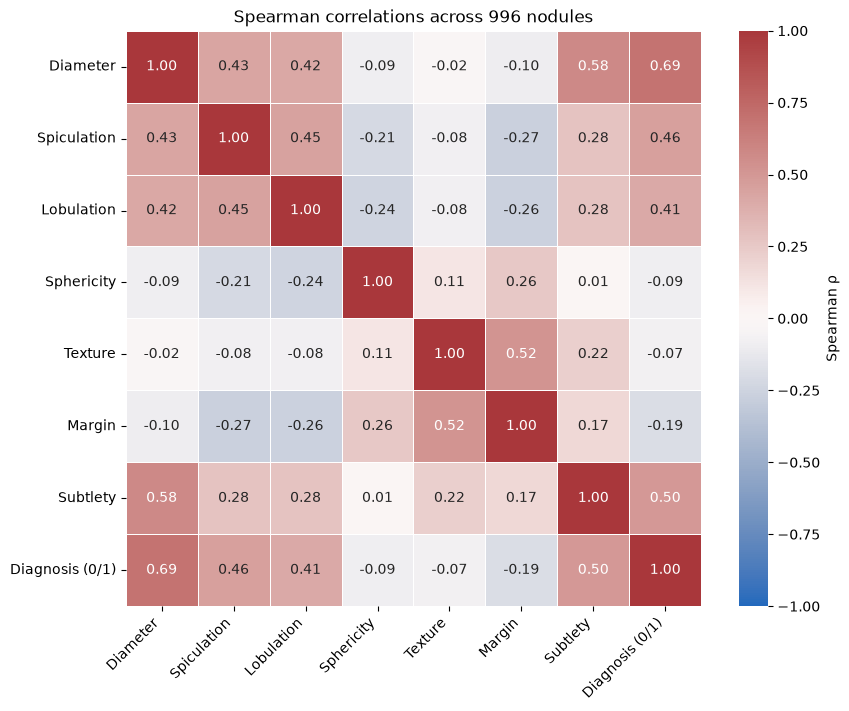

In [16]:
# Use a fixed list of continuous or ordinal features. The diagnosis is the outcome.
correlation_labels = {
    "diameter_mm": "Diameter",
    **dict(zip(feature_columns, features)),
    "Subtlety_value": "Subtlety",
    diagnosis_column: "Diagnosis (0/1)",
}
correlation = (
    nodules[list(correlation_labels)].rename(columns=correlation_labels).corr(method="spearman")
)
diagnosis_correlations = correlation["Diagnosis (0/1)"].drop("Diagnosis (0/1)")
display(diagnosis_correlations.sort_values(key=abs, ascending=False).round(3).to_frame("Spearman ρ"))

fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")
sns.heatmap(
    correlation, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0,
    square=True, linewidths=0.5, cbar_kws={"label": "Spearman ρ"}, ax=ax,
)
ax.set_title("Spearman correlations across 996 nodules")
ax.tick_params(axis="x", labelrotation=45)
for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")
ax.tick_params(axis="y", labelrotation=0)
fig.savefig(results_dir / "eda_spearman_correlations.png", dpi=220)
plt.show()

Diameter has the strongest association with the vote-derived diagnosis (ρ = 0.69).
Subtlety (0.50), spiculation (0.46), and lobulation (0.41) also show positive
associations. Margin has a weaker negative association (−0.19), and sphericity and
texture have weak associations. Spearman correlation compares ranks, which suits the
ordered scores. These are unadjusted associations within this sample.

The course dataset description (Metadata, pp. 4–5) defines diagnosis from the
radiologists’ malignancy ratings. To prevent target leakage, the matrix excludes
`Malignancy_value` and its text label. It also excludes IDs, coordinates, and
numerical codes for nominal categories.

### 4. Agreement between annotations of the same nodule

,Nodules with 2+ ratings,Within-nodule pairs,Unanimous nodules,Unanimous (%),Exact pair agreement (%)
Rating,,,,,
Malignancy rating,996,5073,136,13.7,38.1
Spiculation,996,5073,329,33.0,54.5
Lobulation,996,5073,210,21.1,45.1
Sphericity,996,5073,77,7.7,34.1
Texture,996,5073,525,52.7,71.5
Margin,996,5073,145,14.6,41.2


Ratings split across the >3 cutoff for 520 of 996 nodules.
Workbook labels differing from the documented voting rule: 0.


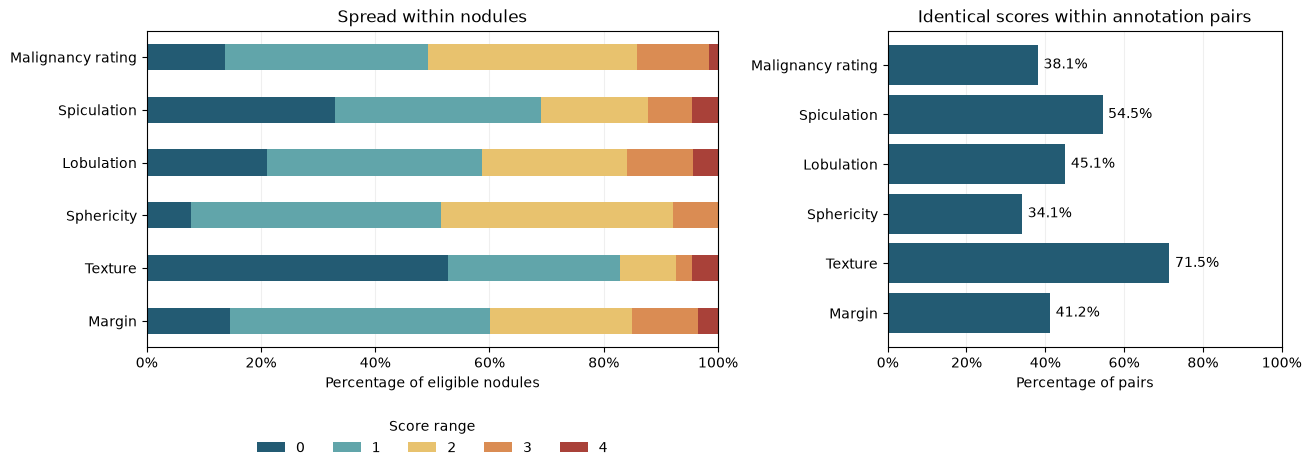

In [17]:
# Reuse the annotation workbook loaded by the original analysis above.
annotations = df
agreement_labels = {"Malignancy_value": "Malignancy rating",
                    **dict(zip(feature_columns, features))}
required_annotations = set(nodule_keys + ["anotation_id"] + list(agreement_labels))
missing_columns = sorted(required_annotations - set(annotations.columns))
if missing_columns:
    raise ValueError(f"Annotation workbook is missing columns: {missing_columns}")
if annotations.duplicated(nodule_keys + ["anotation_id"]).any():
    raise ValueError("Repeated annotation IDs within a nodule. Review the annotation workbook.")
annotation_keys = pd.MultiIndex.from_frame(annotations[nodule_keys].drop_duplicates())
voting_keys = pd.MultiIndex.from_frame(nodules[nodule_keys])
if len(annotation_keys.symmetric_difference(voting_keys)):
    raise ValueError("The annotation and voting workbooks contain different nodule keys.")

agreement_rows = []
spread_counts = {}
for column, label in agreement_labels.items():
    rated = annotations.dropna(subset=[column])
    by_nodule = rated.groupby(nodule_keys)[column].agg(["count", "min", "max"])
    eligible = by_nodule.loc[by_nodule["count"].ge(2)]
    spread = eligible["max"] - eligible["min"]
    if not spread.isin(range(5)).all():
        raise ValueError(f"Unexpected score range for {column}.")
    counts_per_score = rated.groupby(nodule_keys + [column]).size()
    exact_pairs = (counts_per_score * (counts_per_score - 1) // 2).sum()
    total_pairs = (eligible["count"] * (eligible["count"] - 1) // 2).sum()
    spread_counts[label] = spread.value_counts().reindex(range(5), fill_value=0)
    agreement_rows.append({
        "Rating": label,
        "Nodules with 2+ ratings": len(eligible),
        "Within-nodule pairs": total_pairs,
        "Unanimous nodules": int(spread.eq(0).sum()),
        "Unanimous (%)": spread.eq(0).mean() * 100,
        "Exact pair agreement (%)": exact_pairs / total_pairs * 100,
    })
agreement = pd.DataFrame(agreement_rows).set_index("Rating")
display(agreement.round(1))

suspicious_votes = (
    annotations.assign(suspicious=annotations["Malignancy_value"].gt(3))
    .dropna(subset=["Malignancy_value"])
    .groupby(nodule_keys)["suspicious"].agg(["sum", "size"])
)
split_votes = suspicious_votes["sum"].gt(0) & suspicious_votes["sum"].lt(suspicious_votes["size"])
print(f"Ratings split across the >3 cutoff for {split_votes.sum():,} of "
      f"{len(split_votes):,} nodules.")
rule_labels = suspicious_votes["sum"].ge(2).astype(int)
observed_labels = nodules.set_index(nodule_keys)[diagnosis_column]
n_label_differences = observed_labels.ne(rule_labels.reindex(observed_labels.index)).sum()
print(f"Workbook labels differing from the documented voting rule: {n_label_differences:,}.")

spread_table = pd.DataFrame(spread_counts).T
spread_pct = spread_table.div(spread_table.sum(axis=1), axis=0) * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), layout="constrained",
                         gridspec_kw={"width_ratios": [1.45, 1]})
spread_pct.plot.barh(
    stacked=True, color=["#235B73", "#61A5AA", "#E8C26E", "#DA8C53", "#A94139"],
    ax=axes[0], legend=False,
)
axes[0].legend(title="Score range", ncols=5, loc="upper center", bbox_to_anchor=(0.5, -0.19),
               frameon=False)
axes[0].set(title="Spread within nodules", xlabel="Percentage of eligible nodules", ylabel="")
pair_bars = axes[1].barh(agreement.index, agreement["Exact pair agreement (%)"], color="#235B73")
axes[1].bar_label(pair_bars, fmt="%.1f%%", padding=4)
axes[1].set(title="Identical scores within annotation pairs", xlabel="Percentage of pairs")
for ax in axes:
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
fig.savefig(results_dir / "eda_annotation_agreement.png", dpi=220)
plt.show()

The workbook contains 3,674 annotations across 996 nodules, with 3–9 per nodule. The range is the highest minus lowest
rating per nodule. A range of zero means unanimity. Only 136 nodules (13.7%) had
unanimous malignancy ratings, and 38.1% of within-nodule annotation pairs gave the
same malignancy score. Texture had the highest exact pair agreement (71.5%) and
sphericity the lowest (34.1%) among the ratings examined.

For 520 nodules (52.2%), annotations fell on both sides of the suspicious cutoff
(score > 3). Applying the documented rule of at least two suspicious votes
reproduced all 996 workbook labels.

The pair measure gives more weight to nodules with more annotations. The workbook
identifies individual annotations but has no persistent reader ID, so reader-specific
agreement and repeated ratings by the same reader cannot be determined. The percentages
report observed agreement without adjusting for chance.

### 5. CT and VOI slices with segmentation masks

,CT pairs,VOI pairs
Diagnosis_group,,
Benign,2,650
Malign,4,344


VOI masks without images: LIDC-IDRI-1002_R_1.nii.gz, LIDC-IDRI-1002_R_2.nii.gz
VOI images without masks: None


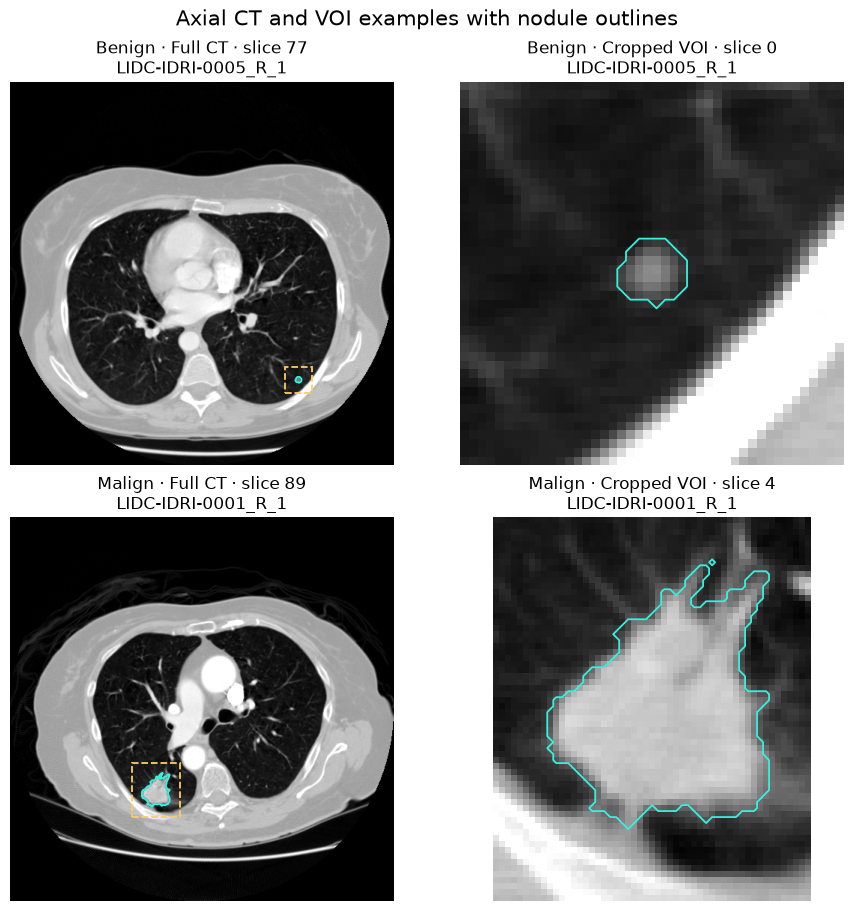

In [18]:
ct_root, voi_root = DATASET_DIR / "CT", DATASET_DIR / "VOIs"
image_folders = [root / subfolder for root in (ct_root, voi_root)
                 for subfolder in ("image", "nodule_mask")]
missing_folders = [path for path in image_folders if not path.is_dir()]
if missing_folders:
    raise FileNotFoundError("Missing imaging folders: " + ", ".join(map(str, missing_folders)))

imaging = nodules[nodule_keys + ["Diagnosis_group"]].copy()
imaging["nodule_file"] = (
    imaging["patient_id"] + "_R_" + imaging["nodule_id"].astype(str) + ".nii.gz"
)
ct_images, ct_masks, voi_images, voi_masks = [
    {path.name for path in folder.glob("*.nii.gz") if path.is_file()} for folder in image_folders
]
imaging["has_ct_pair"] = (
    (imaging["patient_id"] + ".nii.gz").isin(ct_images) & imaging["nodule_file"].isin(ct_masks)
)
imaging["has_voi_pair"] = imaging["nodule_file"].isin(voi_images & voi_masks)
display(imaging.groupby("Diagnosis_group")[["has_ct_pair", "has_voi_pair"]].sum()
        .reindex(diagnosis_order).rename(columns={"has_ct_pair": "CT pairs", "has_voi_pair": "VOI pairs"}))
print("VOI masks without images:", ", ".join(sorted(voi_masks - voi_images)) or "None")
print("VOI images without masks:", ", ".join(sorted(voi_images - voi_masks)) or "None")

def plot_masked_slice(ax, image_path, mask_path, *, mark_location=False):
    image = nib.load(image_path)
    mask = nib.load(mask_path)
    if (len(image.shape) != 3 or image.shape != mask.shape
            or not np.allclose(image.affine, mask.affine, rtol=0, atol=1e-4)):
        raise ValueError(f"Image and mask grids do not match: {image_path.name}, {mask_path.name}")
    image, mask = map(nib.as_closest_canonical, (image, mask))
    mask_data = np.asarray(mask.dataobj) > 0
    area_per_slice = np.count_nonzero(mask_data, axis=(0, 1))
    if not area_per_slice.any():
        raise ValueError(f"Empty segmentation mask: {mask_path.name}")
    slice_index = int(area_per_slice.argmax())
    mask_slice = mask_data[:, :, slice_index].T
    image_slice = np.asarray(image.dataobj[:, :, slice_index]).T.copy()
    dx, dy = image.header.get_zooms()[:2]
    ax.imshow(image_slice, cmap="gray", origin="lower", vmin=-1000, vmax=400, aspect=dy / dx)
    # Pad to draw a closed contour even when the segmentation touches the edge.
    ax.contour(
        np.arange(-1, mask_slice.shape[1] + 1), np.arange(-1, mask_slice.shape[0] + 1),
        np.pad(mask_slice, 1), levels=[0.5], colors=["#35F1DE"], linewidths=1.3,
    )
    ax.set(xlim=(-0.5, mask_slice.shape[1] - 0.5), ylim=(-0.5, mask_slice.shape[0] - 0.5))
    if mark_location:
        rows, cols = np.where(mask_slice)
        padding = 14
        ax.add_patch(Rectangle(
            (cols.min() - padding, rows.min() - padding),
            np.ptp(cols) + 2 * padding, np.ptp(rows) + 2 * padding,
            edgecolor="#FFCC61", facecolor="none", linewidth=1.3, linestyle="--",
        ))
    ax.set_axis_off()
    return slice_index

fig, axes = plt.subplots(2, 2, figsize=(9, 9), layout="constrained")
for row, group in enumerate(diagnosis_order):
    group_images = imaging.loc[imaging["Diagnosis_group"].eq(group)].sort_values(nodule_keys)
    both_pairs = group_images.loc[group_images["has_ct_pair"] & group_images["has_voi_pair"]]
    for col, (root, pair_column, name) in enumerate(
        [(ct_root, "has_ct_pair", "Full CT"), (voi_root, "has_voi_pair", "Cropped VOI")]
    ):
        ax = axes[row, col]
        candidates = both_pairs if not both_pairs.empty else group_images.loc[group_images[pair_column]]
        if candidates.empty:
            ax.text(0.5, 0.5, f"No matched {name} pair\nfor {group}", ha="center", va="center")
            ax.set_axis_off()
            continue
        case = candidates.iloc[0]
        mask_name = case["nodule_file"]
        image_name = case["patient_id"] + ".nii.gz" if col == 0 else mask_name
        index = plot_masked_slice(
            ax, root / "image" / image_name, root / "nodule_mask" / mask_name,
            mark_location=(col == 0),
        )
        ax.set_title(f"{group} · {name} · slice {index}\n{mask_name.removesuffix('.nii.gz')}")
fig.suptitle("Axial CT and VOI examples with nodule outlines", fontsize=15)
fig.savefig(results_dir / "eda_ct_voi_mask_examples.png", dpi=220)
plt.show()

The examples use a full CT and cropped VOI for one nodule from each diagnosis group.
The cyan line traces the mask, and the dashed gold box locates it on the full CT.
Images and masks are checked for matching voxel grids and reoriented with NiBabel
before selecting the axial slice with the largest segmented area in each volume.
[NiBabel’s orientation documentation](https://nipy.org/nibabel/image_orientation.html)

The sample contains three full CT volumes with six matched nodule masks (two Benign
and four Malign). The cropped VOI sample has 994 matched pairs (650 Benign and 344
Malign). The Malign nodules `LIDC-IDRI-1002_R_1` and `LIDC-IDRI-1002_R_2` have masks
but are missing their corresponding VOI images. All 996 nodules remain in the tabular
analyses.